In [2]:
# importar biblioteca
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
# carregar arquivos
plans = pd.read_csv('https://practicum-content.s3.us-west-1.amazonaws.com/datasets/plans.csv')
users = pd.read_csv('https://practicum-content.s3.us-west-1.amazonaws.com/datasets/users_brasil.csv')
usage = pd.read_csv('https://practicum-content.s3.us-west-1.amazonaws.com/datasets/usage.csv')

In [4]:
# mostrar as primeiras 5 linhas de plans
plans.head(5)

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [5]:
# mostrar as primeiras 5 linhas de users
users.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Santos,38,São Paulo,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Matheus,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Valentina,Souza,57,Brasília,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Matheus,Souza,69,Rio de Janeiro,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Matheus,Torres,63,Fortaleza,2022-01-02 02:17:11.657914478,Basico,NaN


In [6]:
# mostrar as primeiras 5 linhas de usage
usage.head(5)

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


In [7]:

# revisar o número de linhas e colunas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)


plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [8]:
# inspeção de plans com .info()
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 260.0+ bytes


In [9]:
# inspeção de users com .info()
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [10]:
# inspeção de usage com .info()
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


In [11]:
# quantidade de valores ausentes para users
print(users.isna().sum())
print(users.isna().mean() * 100)

user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64
user_id        0.000
first_name     0.000
last_name      0.000
age            0.000
city          11.725
reg_date       0.000
plan           0.000
churn_date    88.350
dtype: float64


In [12]:
# quantidade de valores ausentes para usage
print(usage.isna().sum())
print(usage.isna().mean() * 100)

id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64
id           0.000
user_id      0.000
type         0.000
date         0.125
duration    55.190
length      44.740
dtype: float64








  **Valores ausentes**



  **users**
  - `city`: 469 ausentes (11,73%).
  - `churn_date`: 3.534 ausentes (88,35%).

  **usage**
  - `date`: 50 ausentes (0,125%).
  - `duration`: 22.076 ausentes (55,19%).
  - `length`: 17.896 ausentes (44,74%).

  **plans**: sem valores ausentes.
- `city` (users): manter como ausente. Está na faixa de 5–30%, e inventar uma cidade distorceria a análise geográfica. 
- `churn_date` (users): ignorar, sem remover nem imputar. O valor ausente não é erro, significa que o cliente não cancelou (ainda é ativo). Vale a proporção alta, e a coluna será usada para identificar o churn.
- `date` (usage): remover ou manter como NA. É menos de 5% (0,125%), um impacto mínimo, e não dá para imputar uma data de forma confiável.
- `duration` (usage): ignorar, sem imputar. Provavelmente é ausente porque só as chamadas têm duração, e as mensagens não. Isso precisa ser confirmado cruzando com a coluna `type`.
- `length` (usage): ignorar, sem imputar. Segue a mesma lógica: provavelmente só as mensagens têm comprimento, e as chamadas não. Também precisa ser confirmado com `type`.
  


In [13]:
# explorar colunas numéricas de users
print(users.describe())
print(users.median(numeric_only=True))

            user_id          age
count   4000.000000  4000.000000
mean   11999.500000    33.739750
std     1154.844867   123.232257
min    10000.000000  -999.000000
25%    10999.750000    32.000000
50%    11999.500000    47.000000
75%    12999.250000    63.000000
max    13999.000000    79.000000
user_id    11999.5
age           47.0
dtype: float64


**users**
- A coluna `user_id` vai de 10000 a 13999, com 4000 valores, e a média é igual à mediana (11999,5). Isso indica IDs sequenciais, sem sentinels nem valores estranhos. 
- A coluna `age` tem mínimo de -999, que é um sentinel (idade negativa é impossível). Isso distorce a média (33,7), que ficou bem abaixo da mediana (47). Fora o sentinel, os valores parecem razoáveis (máximo de 79 e quartis de 32, 47 e 63).

In [14]:
# explorar colunas numéricas de usage
print(usage.describe())
print(usage.median(numeric_only=True))

                id       user_id      duration        length
count  40000.00000  40000.000000  17924.000000  22104.000000
mean   20000.50000  12002.405975      5.202237     52.127398
std    11547.14972   1157.279564      6.842701     56.611183
min        1.00000  10000.000000      0.000000      0.000000
25%    10000.75000  10996.000000      1.437500     37.000000
50%    20000.50000  12013.000000      3.500000     50.000000
75%    30000.25000  13005.000000      6.990000     64.000000
max    40000.00000  13999.000000    120.000000   1490.000000
id          20000.5
user_id     12013.0
duration        3.5
length         50.0
dtype: float64


**usage**
- As colunas `id` e `user_id` não têm problemas. O `id` vai de 1 a 40000, sequencial, e o `user_id` vai de 10000 a 13999, a mesma faixa de `users`, o que sugere que os registros se conectam corretamente.
- A coluna `duration` não tem sentinels. Os valores vão de 0 a 120, e a média (5,2) está acima da mediana (3,5), indicando distribuição assimétrica à direita. O máximo de 120 está muito acima do percentil 75 (6,99) e pode ser um outlier, a ser avaliado nos boxplots.
- A coluna `length` não tem sentinels, mas o máximo de 1490 é muito maior que o percentil 75 (64) e a mediana (50), o que sugere um outlier. O mínimo de 0 também merece atenção. Também será avaliado nos boxplots.

In [15]:
# explorar colunas categóricas de users
colunas_user = ['city', 'plan']

for col in colunas_user:
    print("Coluna:", col)
    print(users[col].value_counts(dropna=False))
    print()






Coluna: city
city
Rio de Janeiro    808
Brasília          730
São Paulo         616
NaN               469
Fortaleza         450
Floripa           424
Belém             407
?                  96
Name: count, dtype: int64

Coluna: plan
plan
Basico     2595
Premium    1405
Name: count, dtype: int64



In [16]:

# explorar coluna categórica de usage
usage['type'].value_counts(dropna=False)





type
text    22092
call    17908
Name: count, dtype: int64

- A coluna `city` tem 6 cidades válidas, além de 469 valores ausentes (NaN) e 96 ocorrências de "?", que é um sentinel. Depois de converter os "?" para ausente, o total de cidades faltantes sobe para 565 (14,1% dos 4000 usuários). Também vale notar que aparece "Floripa", um apelido de Florianópolis. Não há duplicidade (só existe essa forma), então não é um problema para a análise.
- A coluna `plan` tem apenas dois valores, Basico (2595) e Premium (1405), sem ausentes, sem sentinels e sem variações de escrita.

- A coluna `type` tem apenas dois valores, text (22092) e call (17908), somando os 40000 registros, sem ausentes e sem valores estranhos.


In [17]:
# Converter para data a coluna `reg_date` de users
users['reg_date'] = pd.to_datetime(users['reg_date'], errors='coerce')

In [18]:
# Converter para data a coluna `date` de usage
usage['date'] = pd.to_datetime(usage['date'], errors='coerce')

In [19]:
# Revisar os anos presentes em `reg_date` de users
users['reg_date'].dtype
users['reg_date'].isna().sum()


np.int64(0)

Em `reg_date`, todas as 4000 datas foram convertidas com sucesso 0 valores inválidos. 

In [20]:

# Revisar os anos presentes em `reg_date` de users
users['reg_date'].dt.year.value_counts().sort_index()




reg_date
2022    1314
2023    1316
2024    1330
2026      40
Name: count, dtype: int64

Em `reg_date`, todas as 4000 datas foram convertidas com sucesso, e os registros se concentram em 2022 (1314), 2023 (1316) e 2024 (1330), distribuídos de forma equilibrada. Porém, aparecem 40 registros com o ano 2026, que é uma data impossível, pois os dados foram registrados somente até 2024. Isso indica um erro de captura. 
Basearemos a análise nessas datas.

✍️ **Comentário**: 

**Datas fora do intervalo esperado**

- Aparecem anos impossíveis?
  - Sim, em `reg_date` (users): 40 registros com ano 2026, posterior ao limite de 2024.

- O que você faria com eles?
  - Marcar essas datas como ausentes (pd.NA). Não faz sentido corrigir para uma data "provável", porque não há como saber a data real. Manter os usuários no dataset, apenas sem a data de cadastro.

In [21]:
# Revisar os anos presentes em `date` de usage
usage['date'].dt.year.value_counts().sort_index()

date
2024.0    39950
Name: count, dtype: int64

Em `date`, todas as 39.950 datas válidas pertencem ao ano de 2024, dentro do intervalo esperado. Não aparecem anos futuros nem muito antigos. Os 50 registros restantes já eram valores ausentes desde a etapa 2.1 (a conversão não gerou novos inválidos).

In [22]:
# Substituir -999 pela mediana de age
age_mediana = users.loc[users['age'] != -999, 'age'].median()
users['age'] = users['age'].replace(-999, age_mediana)

# Verificar alterações
users['age'].describe()

count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [23]:
# Substituir ? por NA em city
users['city'] = users['city'].replace('?', pd.NA)

# Verificar alterações
users['city'].value_counts(dropna=False)


city
Rio de Janeiro    808
Brasília          730
São Paulo         616
NaN               469
Fortaleza         450
Floripa           424
Belém             407
<NA>               96
Name: count, dtype: int64

In [24]:
# Marcar datas futuras como NA para reg_date
users.loc[users['reg_date'].dt.year > 2024, 'reg_date'] = pd.NaT

# Verificar alterações
users['reg_date'].dt.year.value_counts(dropna=False).sort_index()



reg_date
2022.0    1314
2023.0    1316
2024.0    1330
NaN         40
Name: count, dtype: int64

In [25]:
# Verificação MAR em usage (Missing At Random) para duration
usage['duration'].isna().groupby(usage['type']).mean() * 100


type
call     0.000000
text    99.927576
Name: duration, dtype: float64

In [26]:
# Verificação MAR em usage (Missing At Random) para length
usage['length'].isna().groupby(usage['type']).mean() * 100


type
call    99.932991
text     0.000000
Name: length, dtype: float64

Dê dois cliques aqui e escreva seu diagnóstico sobre os valores ausentes em `duration` e `length`.
Os valores ausentes de `duration` e `length` são MAR, pois dependem da coluna `type`. Em `duration`, 0% dos registros `call` estão ausentes contra 99,93% dos `text`. Em `length`, ocorre o inverso: 99,93% dos `call` estão ausentes contra 0% dos `text`. Isso faz sentido, já que chamadas só têm duração e mensagens só têm comprimento, então os ausentes não são erro de captura. Existem poucos registros inconsistentes (16 mensagens com `duration` preenchida e 12 chamadas com `length` preenchida, cerca de 0,07% do tipo correspondente), com impacto desprezível.

**Decisão:** manter os valores ausentes, sem imputar. Preencher com média ou mediana criaria durações para mensagens e comprimentos para chamadas, o que não existe na realidade e distorceria as estatísticas.

In [27]:
# Colunas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) # conhecer o total de mensagens
usage["is_call"] = (usage["type"] == "call").astype(int) # conhecer o total de chamadas


# Agrupar informações por usuário
usage_agg = usage.groupby('user_id').agg({
    'is_text': 'sum',
    'is_call': 'sum',
    'duration': 'sum'
}).reset_index()

# observar resultado
usage_agg.head(3)

,user_id,is_text,is_call,duration
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [28]:

# Renomear colunas
usage_agg = usage_agg.rename(columns={
    'is_text': 'quant_mensagens',
    'is_call': 'quant_chamadas',
    'duration': 'quant_minutos_chamada'
})

# observar resultado
usage_agg.head(3)

,user_id,quant_mensagens,quant_chamadas,quant_minutos_chamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [29]:
# Combinar a tabela agregada com o dataset de usuários
user_profile = users.merge(usage_agg, on='user_id', how='left')
user_profile.head(5)


,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,quant_mensagens,quant_chamadas,quant_minutos_chamada
0,10000,Carlos,Santos,38,São Paulo,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70
1,10001,Matheus,Torres,53,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18
2,10002,Valentina,Souza,57,Brasília,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74
3,10003,Matheus,Souza,69,Rio de Janeiro,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99
4,10004,Matheus,Torres,63,Fortaleza,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01


In [30]:
# Resumo estatístico das colunas numéricas
colunas_num = ['age', 'quant_mensagens', 'quant_chamadas', 'quant_minutos_chamada']
user_profile[colunas_num].describe()


,age,quant_mensagens,quant_chamadas,quant_minutos_chamada
count,4000.000000,3999.000000,3999.000000,3999.000000
mean,48.136000,5.524381,4.478120,23.317054
std,17.689919,2.358416,2.144238,18.168095
min,18.000000,0.000000,0.000000,0.000000
25%,33.000000,4.000000,3.000000,11.120000
50%,48.000000,5.000000,4.000000,19.780000
75%,63.000000,7.000000,6.000000,31.415000
max,79.000000,17.000000,15.000000,155.690000


In [31]:
# Distribuição percentual do tipo de plan
user_profile['plan'].value_counts(normalize=True) * 100



plan
Basico     64.875
Premium    35.125
Name: proportion, dtype: float64

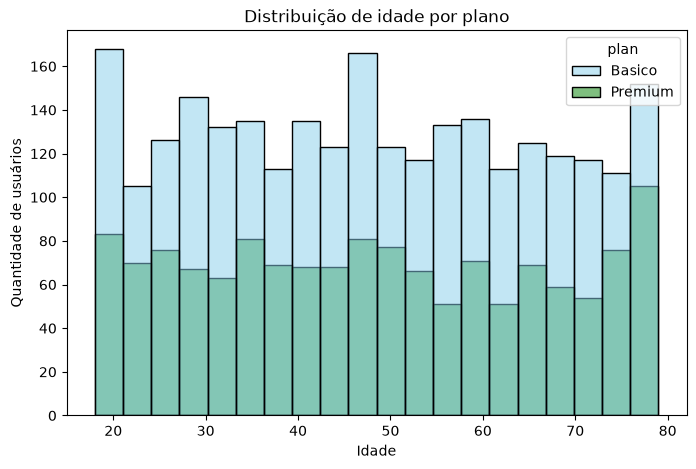

In [32]:
# Histograma para visualizar a idade (age)
plt.figure(figsize=(8, 5))
sns.histplot(data=user_profile, x='age', hue='plan', palette=['skyblue', 'green'], hue_order=['Basico', 'Premium'], bins=20)
plt.title('Distribuição de idade por plano')
plt.xlabel('Idade')
plt.ylabel('Quantidade de usuários')
plt.show()

💡Insights:

- Distribuição aproximadamente uniforme e simétrica: as idades se distribuem de forma bastante parecida entre 18 e 79 anos, sem concentração marcante em uma faixa etária e sem cauda para nenhum dos lados. Isso é coerente com a média (48,1) praticamente igual à mediana (48).
- Os dois planos seguem o mesmo padrão ao longo das idades. As barras do Basico são mais altas simplesmente porque há mais usuários nesse plano (64,9% contra 35,1% no Premium), e não porque exista uma faixa etária que prefira um plano específico.
- Não existe um padrão claro de idade por plano. Há pequenas oscilações (por exemplo, picos perto dos 18-20 anos e dos 47 anos no Basico, e uma barra mais alta do Premium na faixa final, perto dos 78-79 anos), mas elas parecem variação normal, sem uma tendência definida.

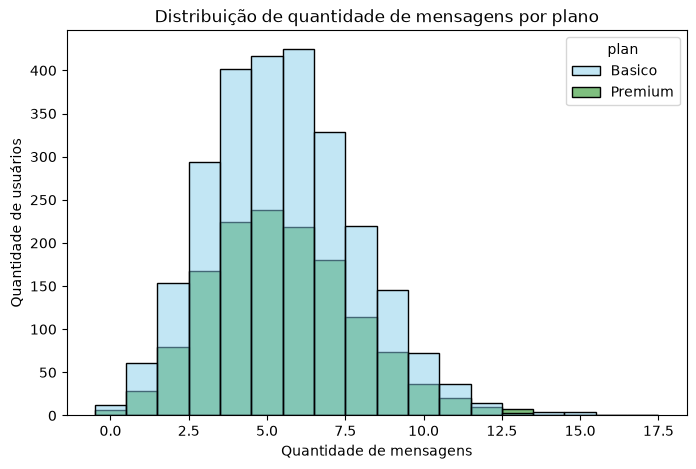

In [33]:
# Histograma para visualizar quant_mensagens
plt.figure(figsize=(8, 5))
sns.histplot(data=user_profile, x='quant_mensagens', hue='plan', palette=['skyblue', 'green'], hue_order=['Basico', 'Premium'], discrete=True)
plt.title('Distribuição de quantidade de mensagens por plano')
plt.xlabel('Quantidade de mensagens')
plt.ylabel('Quantidade de usuários')
plt.show()

💡Insights:

- Distribuição aproximadamente simétrica, com leve assimetria à direita: a maioria dos usuários envia entre 4 e 7 mensagens, com pico em torno de 5 e 6. Existe uma cauda longa à direita, com poucos usuários chegando a 12-17 mensagens. Isso é coerente com a média (5,5) um pouco acima da mediana (5).
- Os dois planos têm praticamente o mesmo formato e o pico no mesmo ponto (por volta de 5 mensagens). As barras do Basico são mais altas apenas porque há mais usuários nesse plano (64,9% contra 35,1%). Não há evidência de que os usuários Premium enviem mais ou menos mensagens que os Basico.
- Os usuários com muitas mensagens (acima de 12) são poucos e podem ser candidatos a outliers, a serem avaliados nos boxplots da etapa 5.2.

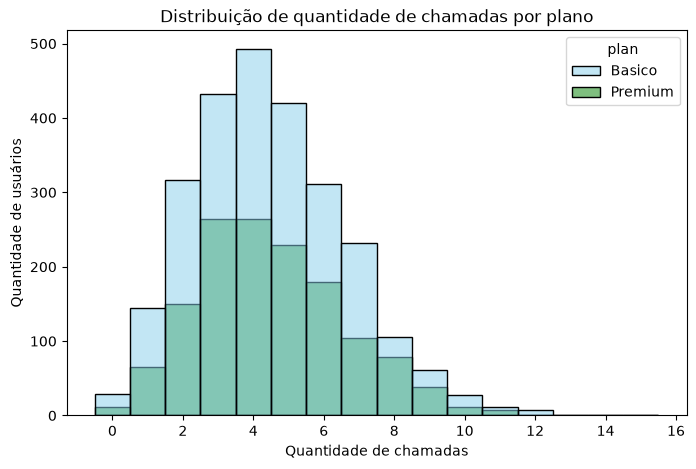

In [34]:
# Histograma para visualizar quant_chamadas
plt.figure(figsize=(8, 5))
sns.histplot(data=user_profile, x='quant_chamadas', hue='plan', palette=['skyblue', 'green'], hue_order=['Basico', 'Premium'], discrete=True)
plt.title('Distribuição de quantidade de chamadas por plano')
plt.xlabel('Quantidade de chamadas')
plt.ylabel('Quantidade de usuários')
plt.show()



💡Insights:

- Distribuição aproximadamente simétrica, com leve assimetria à direita: a maioria dos usuários faz entre 3 e 5 chamadas, com pico em 4. Existe uma cauda à direita, com poucos usuários chegando a 10 chamadas ou mais. Isso é coerente com a média (4,5) um pouco acima da mediana (4).
- Os dois planos têm praticamente o mesmo formato. No Basico o pico está em 4 chamadas, e no Premium as barras de 3 e 4 chamadas têm alturas parecidas. As barras do Basico são mais altas apenas porque há mais usuários nesse plano (64,9% contra 35,1%). Não há evidência de que o plano influencie a quantidade de chamadas.
- Os usuários com muitas chamadas (acima de 10) são poucos e podem ser candidatos a outliers, a serem avaliados nos boxplots da etapa 5.2.

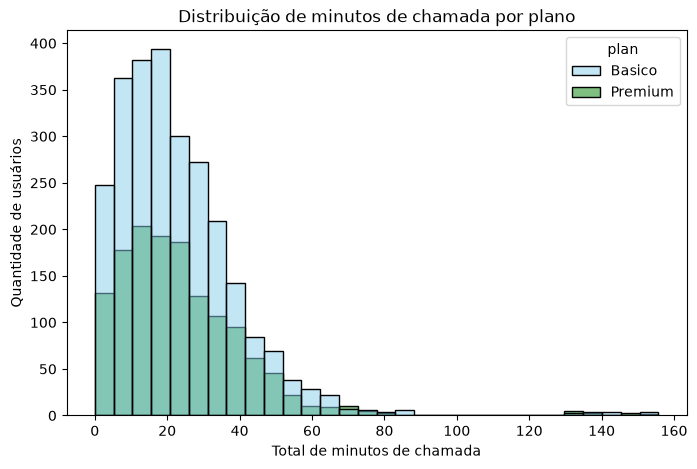

In [35]:
# Histograma para visualizar quant_minutos_chamada
plt.figure(figsize=(8, 5))
sns.histplot(data=user_profile, x='quant_minutos_chamada', hue='plan', palette=['skyblue', 'green'], hue_order=['Basico', 'Premium'], bins=30)
plt.title('Distribuição de minutos de chamada por plano')
plt.xlabel('Total de minutos de chamada')
plt.ylabel('Quantidade de usuários')
plt.show()


💡Insights:

- Distribuição assimétrica à direita: a maioria dos usuários tem um total de minutos de chamada baixo, concentrado entre 5 e 30 minutos, com pico em torno de 15-20. A cauda à direita é longa, com poucos usuários acima de 60 minutos. Isso é coerente com a média (23,3) acima da mediana (19,8).
- Há um pequeno grupo de usuários separado do resto, entre 130 e 155 minutos, bem distante da massa principal (o percentil 75 é 31,4). Esses valores são fortes candidatos a outliers, a serem avaliados nos boxplots da etapa 5.2.
- Os dois planos têm praticamente o mesmo formato, com pico na mesma região. As barras do Basico são mais altas apenas porque há mais usuários nesse plano (64,9% contra 35,1%). Não há evidência de que o plano influencie o total de minutos de chamada.

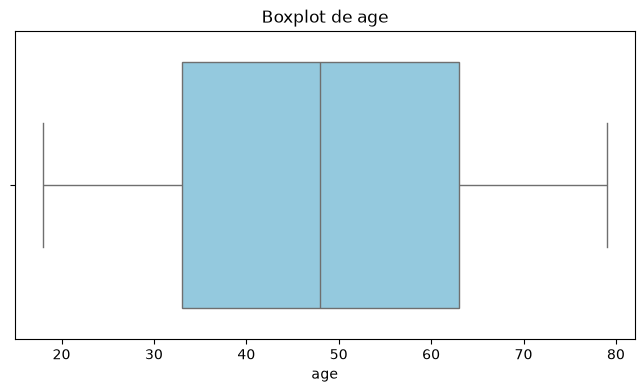

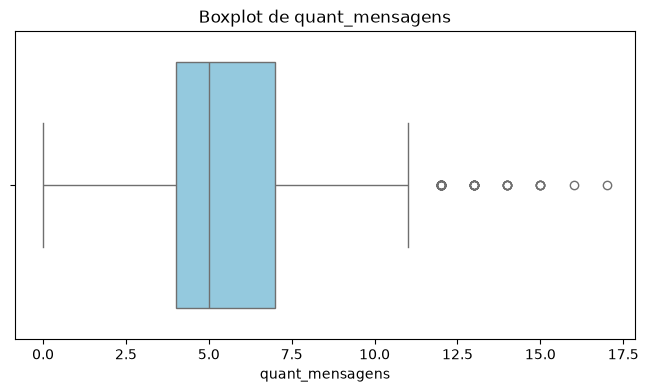

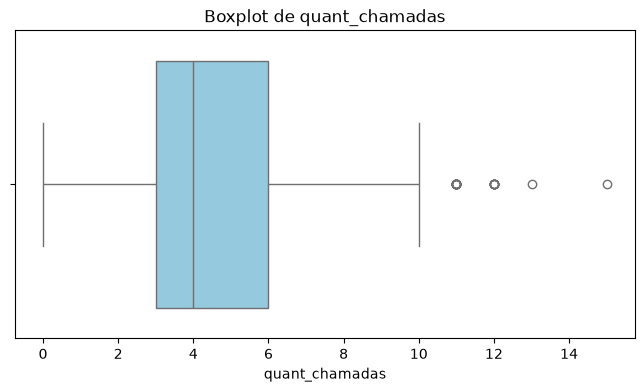

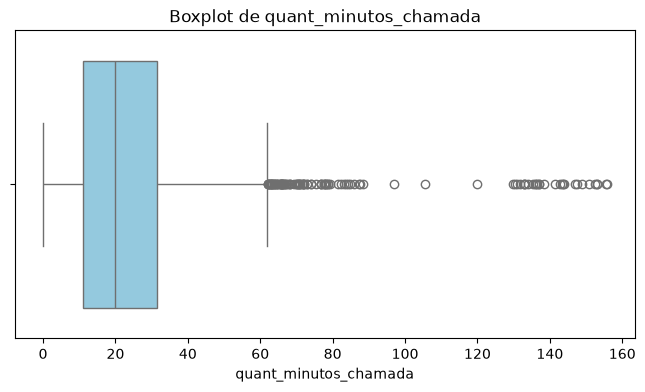

In [36]:
# Visualizar usando BoxPlot
columnas_numericas = ['age', 'quant_mensagens', 'quant_chamadas', 'quant_minutos_chamada']

for col in columnas_numericas:
    plt.figure(figsize=(8, 4))
    sns.boxplot(data=user_profile, x=col, color='skyblue')
    plt.title(f'Boxplot de {col}')
    plt.xlabel(col)
    plt.show()

💡Insights:

- `age`: não há outliers. A caixa é larga e simétrica (mediana 48) e os bigodes cobrem toda a faixa de 18 a 79 anos, o que é coerente com a distribuição uniforme vista no histograma.
- `quant_mensagens`: aparecem outliers apenas à direita, a partir de cerca de 12 mensagens (até 17). São poucos usuários com envio muito acima do típico (mediana 5).
- `quant_chamadas`: também há outliers só à direita, a partir de 11 chamadas (até 15), em pequena quantidade, contra uma mediana de 4.
- `quant_minutos_chamada`: é a variável com mais outliers, todos à direita, acima de cerca de 62 minutos. Há uma sequência de valores entre 62 e 90 e um grupo separado entre 130 e 155 minutos, bem distante da maioria dos usuários (mediana 19,8). Isso confirma a forte assimetria à direita vista no histograma.
- Os valores extremos são plausíveis para o negócio: representam usuários de uso intenso, e não erros de captura (não há valores negativos nem sentinels). Por isso, a sugestão é mantê-los na análise, sem remover nem corrigir, já que podem ser justamente os perfis relevantes para entender o churn e desenhar estratégias de retenção. Nas análises que usam a média, vale lembrar que ela é puxada por esses valores, e a mediana é mais representativa do usuário típico.

In [37]:
# Calcular limites com o método IQR
colunas_limites = ['quant_mensagens', 'quant_chamadas', 'quant_minutos_chamada']

for col in colunas_limites:
    q1 = user_profile[col].quantile(0.25)
    q3 = user_profile[col].quantile(0.75)
    iqr = q3 - q1
    limite_sup = q3 + 1.5 * iqr
    qtd = (user_profile[col] > limite_sup).sum()
    print(f"{col}: limite superior = {limite_sup:.2f} | outliers = {qtd}")




quant_mensagens: limite superior = 11.50 | outliers = 46
quant_chamadas: limite superior = 10.50 | outliers = 30
quant_minutos_chamada: limite superior = 61.86 | outliers = 109


In [38]:
# Revise os limites superiores e o max para decidir se mantém os outliers ou não
user_profile[colunas_limites].describe()

,quant_mensagens,quant_chamadas,quant_minutos_chamada
count,3999.000000,3999.000000,3999.000000
mean,5.524381,4.478120,23.317054
std,2.358416,2.144238,18.168095
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.120000
50%,5.000000,4.000000,19.780000
75%,7.000000,6.000000,31.415000
max,17.000000,15.000000,155.690000


💡Insights:

- quant_mensagens: manter os outliers. O limite superior é 11,5 e há 46 usuários acima dele (cerca de 1,2% da base), com máximo de 17 mensagens. Esse máximo é plausível para um usuário de uso intenso, e não um erro de captura, e o impacto na análise é pequeno.
- quant_chamadas: manter os outliers. O limite superior é 10,5 e há 30 usuários acima dele (cerca de 0,8%), com máximo de 15 chamadas. É um valor realista e a quantidade é muito pequena.
- quant_minutos_chamada: manter os outliers. O limite superior é 61,86 e há 109 usuários acima dele (cerca de 2,7%), com máximo de 155,7 minutos, bem acima do percentil 75 (31,4). Mesmo sendo a coluna com mais outliers, são valores possíveis (usuários que falam muito ao telefone), sem negativos nem sentinels. Remover esses usuários eliminaria justamente os perfis de uso mais intenso, que podem ser relevantes para entender o churn e a retenção.
- Como os outliers são mantidos, a média dessas variáveis fica puxada para cima (por exemplo, 23,3 de média contra 19,8 de mediana em minutos). Nas comparações entre grupos, vale usar a mediana, que representa melhor o usuário típico.

In [39]:
# Criar coluna grupo_uso
condicoes = [
    (user_profile['quant_chamadas'] < 5) & (user_profile['quant_mensagens'] < 5),
    (user_profile['quant_chamadas'] < 10) & (user_profile['quant_mensagens'] < 10)
]
categorias = ['Baixo uso', 'Uso médio']

user_profile['grupo_uso'] = np.select(condicoes, categorias, default='Alto uso')




In [40]:
# verificar alterações
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,quant_mensagens,quant_chamadas,quant_minutos_chamada,grupo_uso
0,10000,Carlos,Santos,38,São Paulo,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso médio
1,10001,Matheus,Torres,53,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso
2,10002,Valentina,Souza,57,Brasília,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso médio
3,10003,Matheus,Souza,69,Rio de Janeiro,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso
4,10004,Matheus,Torres,63,Fortaleza,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Baixo uso


In [41]:
# Criar coluna grupo_idade
condicoes_idade = [
    user_profile['age'] < 30,
    user_profile['age'] < 60
]
categorias_idade = ['Jovem', 'Adulto']

user_profile['grupo_idade'] = np.select(condicoes_idade, categorias_idade, default='Idoso')






In [42]:
# verificar alterações
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,quant_mensagens,quant_chamadas,quant_minutos_chamada,grupo_uso,grupo_idade
0,10000,Carlos,Santos,38,São Paulo,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso médio,Adulto
1,10001,Matheus,Torres,53,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso,Adulto
2,10002,Valentina,Souza,57,Brasília,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso médio,Adulto
3,10003,Matheus,Souza,69,Rio de Janeiro,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso,Idoso
4,10004,Matheus,Torres,63,Fortaleza,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Baixo uso,Idoso


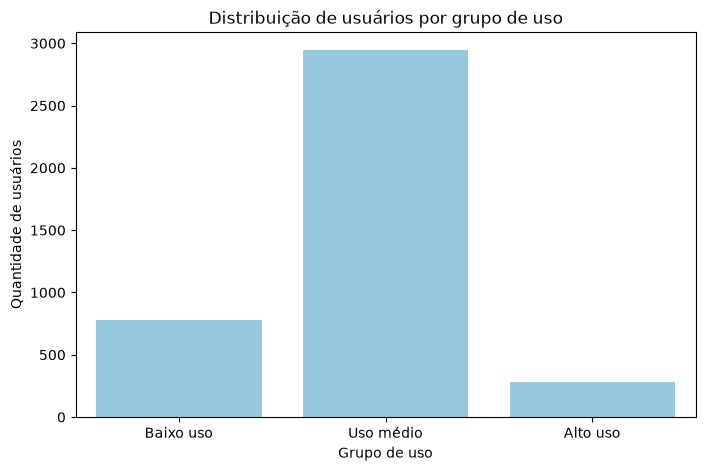

In [43]:
# Visualização dos segmentos por uso
plt.figure(figsize=(8, 5))
sns.countplot(data=user_profile, x='grupo_uso', order=['Baixo uso', 'Uso médio', 'Alto uso'], color='skyblue')
plt.title('Distribuição de usuários por grupo de uso')
plt.xlabel('Grupo de uso')
plt.ylabel('Quantidade de usuários')
plt.show()

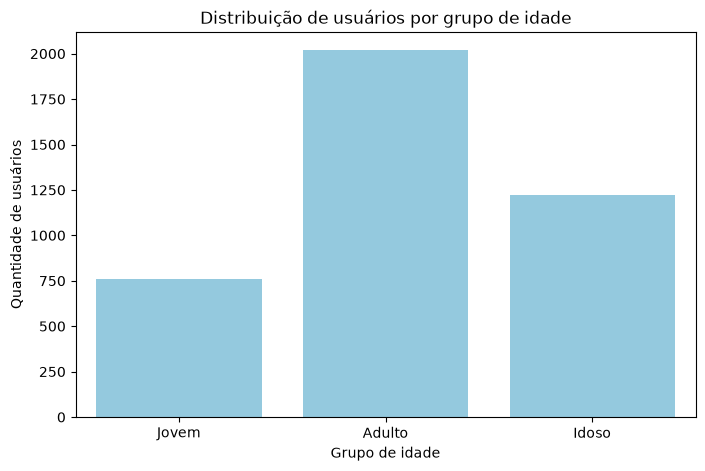

In [44]:
# Visualização dos segmentos por idade
plt.figure(figsize=(8, 5))
sns.countplot(data=user_profile, x='grupo_idade', order=['Jovem', 'Adulto', 'Idoso'], color='skyblue')
plt.title('Distribuição de usuários por grupo de idade')
plt.xlabel('Grupo de idade')
plt.ylabel('Quantidade de usuários')
plt.show()



In [45]:
print(user_profile['grupo_uso'].value_counts())
print(user_profile['grupo_uso'].value_counts(normalize=True) * 100)
print()
print(user_profile['grupo_idade'].value_counts())
print(user_profile['grupo_idade'].value_counts(normalize=True) * 100)

grupo_uso
Uso médio    2943
Baixo uso     778
Alto uso      279
Name: count, dtype: int64
grupo_uso
Uso médio    73.575
Baixo uso    19.450
Alto uso      6.975
Name: proportion, dtype: float64

grupo_idade
Adulto    2018
Idoso     1222
Jovem      760
Name: count, dtype: int64
grupo_idade
Adulto    50.45
Idoso     30.55
Jovem     19.00
Name: proportion, dtype: float64


**Análise executiva**

⚠️ **Problemas detectados nos dados**

- `age` tinha o valor sentinela -999 (idade impossível), que distorcia a média (33,7 contra mediana de 47). Foi substituído pela mediana das idades válidas (48).
- `city` tinha 565 valores faltantes (14,1% dos usuários): 469 ausentes e 96 registros com "?", que foram convertidos para ausente.
- `reg_date` tinha 40 cadastros com ano 2026, data impossível, pois os dados vão até 2024. Foram marcados como ausentes.
- Em `usage`, 50 registros (0,125%) não têm data. Os ausentes de `duration` e `length` não são erro: dependem do tipo de registro (chamadas têm duração, mensagens têm comprimento), mas há cerca de 28 registros inconsistentes. Um usuário não tem nenhum registro de uso.
- Os outliers de uso (acima de 11 mensagens, 10 chamadas ou 62 minutos) são poucos (de 0,8% a 2,7% dos usuários) e plausíveis, então foram mantidos.

🔍 **Segmentos por idade**

- O grupo Adulto (30 a 59 anos) é o maior, com 2.018 usuários (50,5% da base).
- Os Idosos (60 anos ou mais) são o segundo grupo, com 1.222 usuários (30,6%).
- Os Jovens (menos de 30 anos) são o menor grupo, com 760 usuários (19,0%).
- A base é madura: 81% dos usuários têm 30 anos ou mais, e há mais idosos do que jovens.

📊 **Segmentos por nível de uso**

- A grande maioria dos usuários tem Uso médio: 2.943 (73,6%).
- O Baixo uso reúne 778 usuários (19,5%).
- O Alto uso é o menor grupo, com 279 usuários (7,0%).
- O comportamento é bastante homogêneo e concentrado em um uso moderado, sem diferença relevante entre os planos Basico e Premium nas distribuições de uso.

➡️ **Isso sugere que** a base da ConnectaTel é formada, em sua maioria, por clientes adultos de uso moderado, com um grupo pequeno de usuários intensivos (os mais valiosos) e um grupo de baixo uso que pode representar maior risco de cancelamento. Ainda não cruzamos esses segmentos com o churn, então essa relação é uma hipótese a ser confirmada.

💡 **Recomendações**

- Corrigir a captura de dados na origem, com validações para idade, cidade e data de cadastro, para evitar sentinelas, valores "?" e datas futuras.
- Acompanhar de perto o grupo de Baixo uso com ações de engajamento ou ofertas personalizadas, por ser o candidato mais provável a cancelar.
- Criar programas de fidelização e ofertas de upgrade para o grupo de Alto uso, que é pequeno, mas de maior valor.
- Desenhar campanhas segmentadas por faixa de idade, priorizando os Adultos e os Idosos, que concentram 81% da base, e avaliar estratégias para atrair o público Jovem.
- Como próximo passo, cruzar `churn_date` com `grupo_uso`, `grupo_idade` e `plan` para identificar quais segmentos cancelam mais.

Link para o repositório público do projeto: 

https://github.com/camiladmelo-bit/telecom-analysis/tree/main